<div align="center">
  <img src="https://raw.githubusercontent.com/devicons/devicon/master/icons/python/python-original.svg" width="80"/>
</div>

<h1 align="center">Redes Neurais Convolucionais</h1>

<h3 align="center">Notebook 02: CNN com PyTorch</h3>

<p align="center"><b>PhD. Julles Mitoura</b></p>

<div align="center">
  <img src="https://img.shields.io/badge/Python-3776AB?style=for-the-badge&logo=python&logoColor=white"/>
  <img src="https://img.shields.io/badge/Jupyter-F37626?style=for-the-badge&logo=jupyter&logoColor=white"/>
  <img src="https://img.shields.io/badge/PyTorch-EE4C2C?style=for-the-badge&logo=pytorch&logoColor=white"/>
</div>

---

### Onde este notebook se encaixa na aula

| Notebook | Assunto | Ferramenta |
|---|---|---|
| 00 | Como uma rede aprende: erro, derivada e otimização | NumPy |
| 01 | Uma CNN construída do zero, operação por operação | NumPy |
| **02 (você está aqui)** | **CNN com PyTorch em um dataset criado por nós** | **PyTorch** |
| 03 | CNN em datasets reais (MNIST e CIFAR-10) | PyTorch |

> **Pré-requisito:** o notebook `01_cnn_intro.ipynb`. Tudo que o PyTorch fará automaticamente aqui foi escrito na mão lá.

In [1]:
# Instalação das dependências
%pip install numpy matplotlib torch torchvision --quiet


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## O que vamos fazer neste notebook

No notebook 01 escrevemos tudo na mão: a convolução, a ReLU, o pooling e até a derivada de cada operação. Funcionou, mas com duas limitações: era lento, e qualquer operação nova exigiria deduzir a derivada correspondente no papel.

Agora entra o **PyTorch**, a biblioteca usada na indústria e na pesquisa para construir redes neurais. Duas coisas mudam:

| | Notebook 01 (NumPy) | Este notebook (PyTorch) |
|---|---|---|
| **Forward** | escrito por nós, operação por operação | montado com camadas prontas (`nn.Conv2d`, `nn.ReLU`, ...) |
| **Backward** | escrito por nós, derivada por derivada | **automático**, com uma chamada de `loss.backward()` |

A segunda linha é a grande vantagem. O PyTorch anota todas as contas feitas no forward e, quando pedimos, aplica a regra da cadeia sozinho, calculando a derivada da perda em relação a cada um dos milhares de parâmetros. O mecanismo é exatamente o do notebook 01, apenas automatizado, e tem nome: **diferenciação automática** (*autograd*).

### O problema desta vez

Vamos sair dos dois desenhos de 6×6 e passar para o reconhecimento de **dígitos de 0 a 9** em imagens de 28×28 pixels. São 10 classes em vez de 2.

E vamos **criar o nosso próprio dataset**, desenhando os dígitos com código. A intenção é desfazer um mistério comum de quem começa: um dataset não tem nada de mágico, é só **uma pilha de imagens com seus rótulos**. Quem entende como fabricar um entende o que o MNIST do notebook 03 é por dentro.

### Roteiro

| Seção | Conteúdo |
|---|---|
| **1** | Gerando imagens de dígitos com código |
| **2** | Visualizando e conferindo o dataset |
| **3** | Montando a CNN com PyTorch |
| **4** | Treinamento |
| **5** | Avaliação e análise dos erros |
| **6** | Conclusão |

> **Tempo estimado:** 30 minutos. O treinamento leva de um a dois minutos em CPU.

## Bibliotecas e três palavras novas

| Biblioteca | Para que serve aqui |
|---|---|
| `numpy` | criar e manipular as imagens como tabelas de números |
| `matplotlib` | desenhar os dígitos e os gráficos |
| `torch` | a biblioteca de redes neurais |
| `torch.nn` | as camadas prontas (`Conv2d`, `ReLU`, `Linear`, ...) |
| `torch.optim` | os otimizadores, isto é, as versões mais espertas do gradiente descendente |

**Tensor.** É o nome que o PyTorch dá às suas tabelas de números. Um tensor é quase igual a um array do NumPy, com duas diferenças: pode rodar na placa de vídeo e **guarda o histórico das contas**, o que permite o backward automático. Uma lista é um tensor de 1 dimensão, uma imagem em tons de cinza é de 2 dimensões, um lote de imagens coloridas é de 4.

**Device.** Onde as contas acontecem: `cpu` (o processador comum) ou `cuda` (placa de vídeo NVIDIA). Em GPU o treino é bem mais rápido, e a célula abaixo detecta automaticamente o que existe na sua máquina. Se aparecer `cpu`, tudo funciona igual, apenas mais devagar.

**Seed (semente).** Fixar a semente dos sorteios aleatórios com `manual_seed` faz o notebook produzir sempre o mesmo resultado, o que é essencial num material de aula.

In [2]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

# cuda -> gpu nvidia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')

Dispositivo: cpu


## 1. Gerando o nosso dataset de dígitos

A ideia é direta: usamos o matplotlib para **escrever cada dígito dentro de uma imagem de 28×28** e depois estragamos um pouco essa imagem, de propósito. Para cada uma sorteamos:

- **ruído:** valores aleatórios somados a cada pixel, simulando imperfeições;
- **deslocamento:** o dígito aparece um pouco fora do centro;
- **tamanho:** a fonte varia de tamanho.

### Por que estragar as imagens de propósito?

Se todas as imagens do dígito 3 fossem idênticas, a rede poderia simplesmente **decorar** aquela imagem específica e ainda assim ir bem na prova. Na primeira imagem um pouco diferente, erraria. Quando o modelo decora em vez de aprender o padrão, dizemos que houve **overfitting**, e é o problema mais comum de todo o aprendizado de máquina.

Gerar variação obriga a rede a aprender o que realmente define um 3, em vez de guardar uma cópia exata de pixels. Criar variações artificiais assim é uma técnica com nome próprio, **data augmentation**, que reaparece no notebook 03 aplicada ao CIFAR-10.

### Por que não usar logo o MNIST?

Vamos usar, no notebook 03. Mas fabricar um dataset antes deixa três coisas evidentes:

- qualquer imagem é apenas uma **tabela de números**;
- um dataset é apenas um **conjunto dessas tabelas com seus rótulos**;
- o modelo não sabe, e não se importa, se os dados são reais ou fabricados. Ele aprende os padrões que estiverem ali.

In [3]:
def renderizar_digito(digito, tamanho=28, ruido=0.15, seed=None):
    """Gera uma imagem 28x28 de um dígito com ruído e posição variável."""
    rng = np.random.default_rng(seed)

    fig = Figure(figsize=(1, 1), dpi=tamanho)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    ax.set_facecolor('black')
    fig.patch.set_facecolor('black')

    # Variação de posição e tamanho
    dx       = rng.uniform(-0.08, 0.08)
    dy       = rng.uniform(-0.08, 0.08)
    fontsize = rng.integers(16, 22)

    ax.text(0.5 + dx, 0.5 + dy, str(digito),
            ha='center', va='center',
            fontsize=fontsize, color='white', fontweight='bold')

    canvas.draw()
    buf  = canvas.buffer_rgba()
    img  = np.frombuffer(buf, dtype=np.uint8).reshape(tamanho, tamanho, 4)
    gray = img[:, :, 0].astype(float) / 255.0  # canal R = escala de cinza

    # Ruído gaussiano
    gray = np.clip(gray + rng.normal(0, ruido, gray.shape), 0, 1)

    return gray


def gerar_dataset(n_por_classe=300, tamanho=28, ruido=0.10, seed=42):
    """Gera n_por_classe imagens para cada dígito 0-9."""
    X, y = [], []
    for digito in range(10):
        for i in range(n_por_classe):
            img = renderizar_digito(digito, tamanho=tamanho, ruido=ruido,
                                    seed=seed * 1000 + digito * 100 + i)
            X.append(img)
            y.append(digito)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)


print('Funções renderizar_digito e gerar_dataset definidas.')

Funções renderizar_digito e gerar_dataset definidas.


## 2. Visualizando e conferindo o dataset

Primeira regra ao trabalhar com dados: **olhe para eles antes de treinar qualquer coisa**. Erros de geração ou de rótulo são fáceis de achar com os olhos e difíceis de descobrir depois, quando o único sintoma é uma acurácia baixa sem explicação aparente.

Vamos gerar dois conjuntos:

- **3 000 imagens de treino** (300 de cada dígito), usadas para ajustar os pesos;
- **1 000 imagens de teste** (100 de cada dígito), geradas com outra semente e usadas somente para avaliar.

Eles precisam ser separados. Avaliar o modelo nas mesmas imagens em que ele treinou é como corrigir uma prova com o gabarito na mão: o número fica alto e não significa nada.

Gerando dataset de treino (3 000 imagens)...
Gerando dataset de teste  (1 000 imagens)...

Treino : (3000, 28, 28)  |  Teste: (1000, 28, 28)
Rótulos únicos: [0 1 2 3 4 5 6 7 8 9]


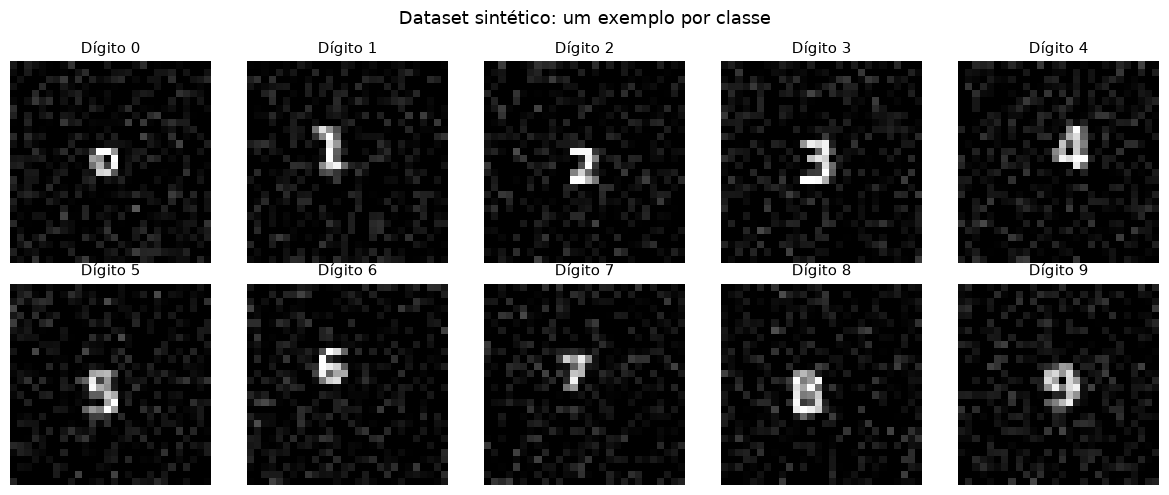

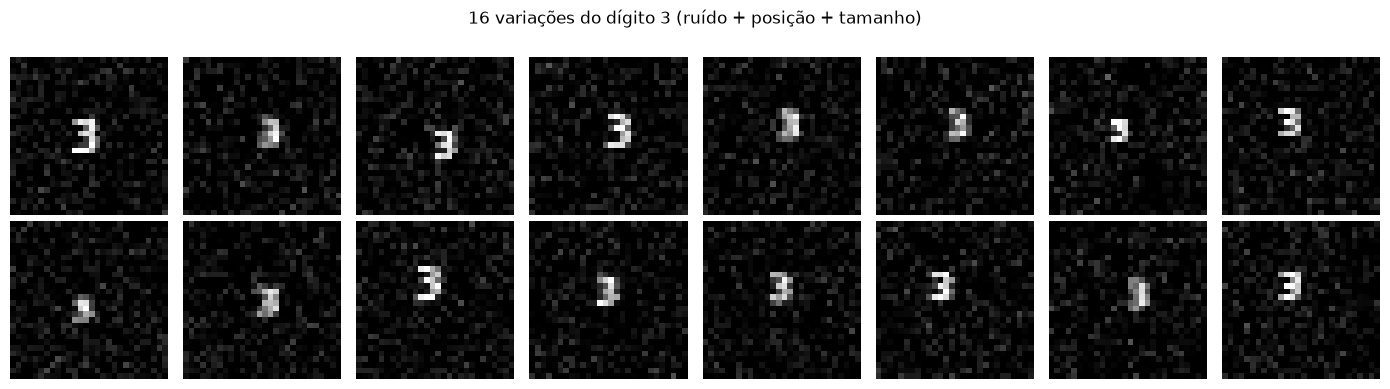

In [4]:
print('Gerando dataset de treino (3 000 imagens)...')
X_train, y_train = gerar_dataset(n_por_classe=300, seed=42)

print('Gerando dataset de teste  (1 000 imagens)...')
X_test, y_test = gerar_dataset(n_por_classe=100, seed=99)

print(f'\nTreino : {X_train.shape}  |  Teste: {X_test.shape}')
print(f'Rótulos únicos: {np.unique(y_train)}')

# Visualizar um exemplo de cada dígito
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for digito, ax in enumerate(axes.flat):
    idx = np.where(y_train == digito)[0][0]
    ax.imshow(X_train[idx], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Dígito {digito}', fontsize=11)
    ax.axis('off')
plt.suptitle('Dataset sintético: um exemplo por classe', fontsize=13)
plt.tight_layout()
plt.show()

# Mostrar variações do mesmo dígito
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for k, ax in enumerate(axes.flat):
    idx = np.where(y_train == 3)[0][k]
    ax.imshow(X_train[idx], cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle('16 variações do dígito 3 (ruído + posição + tamanho)', fontsize=12)
plt.tight_layout()
plt.show()

## 3. A CNN em PyTorch

Mesma receita do notebook 01 (convolução, ReLU, pooling, flatten, densa), agora empilhada com camadas prontas e um pouco mais funda, porque o problema é mais difícil: 10 classes em vez de 2.

| Camada | O que faz | Formato da saída |
|---|---|---|
| `Conv2d(1, 32, 3)` | aplica **32 filtros** diferentes de 3×3 | 32×26×26 |
| `ReLU` | zera os valores negativos | 32×26×26 |
| `MaxPool2d(2)` | mantém o maior valor de cada bloco 2×2 | 32×13×13 |
| `Conv2d(32, 64, 3)` | 64 filtros que procuram combinações dos padrões anteriores | 64×11×11 |
| `ReLU` e `MaxPool2d(2)` | | 64×5×5 |
| `Flatten` | achata tudo numa lista | 1 600 |
| `Linear(1600, 128)` e `ReLU` | camada densa que combina os padrões encontrados | 128 |
| `Dropout(0.25)` | desliga 25% dos neurônios durante o treino | 128 |
| `Linear(128, 10)` | uma nota para cada dígito de 0 a 9 | 10 |

### O que mudou em relação ao notebook 01

**Vários filtros por camada.** Lá tínhamos 1 filtro, aqui a primeira camada tem 32. Cada um aprende a procurar uma coisa diferente (uma borda vertical, uma curva, um canto), e por isso a saída tem 32 tabelas em vez de 1. Cada uma dessas tabelas é um mapa de características.

**Duas camadas convolucionais em sequência.** É a **hierarquia** mencionada no notebook 01: a primeira camada encontra traços simples e a segunda encontra combinações desses traços. É assim que a rede constrói noções cada vez mais abstratas.

**Dropout.** Durante o treino, desliga aleatoriamente uma parte dos neurônios em cada passo. Parece sabotagem, mas impede que a rede fique dependente de poucos neurônios, e é uma das formas mais simples de combater o overfitting. Na avaliação ele é desligado automaticamente.

**Logits.** As 10 saídas finais são números soltos chamados de **logits**, e ainda não são probabilidades. A softmax que faria essa conversão está embutida na função de perda, como explicamos na próxima seção.

### Sobre o formato dos dados

O `Conv2d` do PyTorch espera sempre quatro dimensões, nesta ordem: `(lote, canais, altura, largura)`.

- **lote** (*batch*): quantas imagens são processadas juntas;
- **canais**: 1 para tons de cinza, 3 para colorido (vermelho, verde e azul);
- **altura** e **largura**: 28 e 28 no nosso caso.

In [5]:
class CNN_Digitos(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3),  # (B, 32, 26, 26)
            nn.ReLU(),
            nn.MaxPool2d(2),                  # (B, 32, 13, 13)
            nn.Conv2d(32, 64, kernel_size=3), # (B, 64, 11, 11)
            nn.ReLU(),
            nn.MaxPool2d(2),                  # (B, 64, 5, 5)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 5 * 5, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


modelo = CNN_Digitos().to(device)
total  = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f'Parâmetros treináveis: {total:,}')
print(modelo)

Parâmetros treináveis: 225,034
CNN_Digitos(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 4. Treinamento

Antes de treinar, três preparações.

**1. Converter para tensores e acrescentar a dimensão de canal.** Nossas imagens estão no formato `(3000, 28, 28)` e o PyTorch espera `(3000, 1, 28, 28)`, onde o `1` indica "uma cor só". É exatamente isso que o `unsqueeze(1)` faz.

**2. Criar os DataLoaders.** Um `DataLoader` funciona como um entregador de dados: embaralha os exemplos e os serve em **lotes** (*batches*) de 64. Treinar em lotes, em vez de um exemplo por vez como no notebook 01, é mais rápido (as contas dos 64 saem de uma vez) e mais estável (a correção vem da média do lote, o que reduz o efeito de exemplos esquisitos).

**3. Escolher a perda e o otimizador.**

| Peça | O que usamos | Por quê |
|---|---|---|
| Perda | `CrossEntropyLoss` | é a entropia cruzada do notebook 01, já com a softmax embutida. É por isso que o modelo devolve logits e não probabilidades |
| Otimizador | `Adam`, com `lr=1e-3` | uma versão mais esperta do gradiente descendente |

### O que o Adam faz de diferente

No notebook 00, todos os parâmetros davam passos do mesmo tamanho, definido pela taxa de aprendizado. O **Adam** ajusta o tamanho do passo de cada parâmetro individualmente, com base no histórico recente das derivadas: parâmetro cuja derivada fica mudando de sinal recebe passos menores, parâmetro com derivada consistente recebe passos maiores. Na prática, converge mais rápido e sofre menos com a escolha da taxa de aprendizado. A ideia central continua a mesma: andar no sentido contrário à derivada.

### O loop, linha por linha

```
para cada época:
    para cada lote de 64 imagens:
        logits = modelo(imagens)           # forward
        loss   = criterio(logits, rotulos) # perda
        otimizador.zero_grad()             # zera as derivadas anteriores
        loss.backward()                    # backward automático
        otimizador.step()                  # atualiza os pesos
```

Compare com o notebook 01: é o mesmo ciclo de forward, loss, backward e update. A diferença é que dezenas de contas escritas por nós viraram duas linhas, `loss.backward()` e `otimizador.step()`.

> **Por que `zero_grad()`?** O PyTorch **acumula** as derivadas a cada `backward()`. Sem zerar, o passo atual somaria as derivadas do lote anterior e o treino sairia errado. Esquecer essa linha é um dos erros mais comuns de quem está começando.

In [6]:
# Converter para tensores e adicionar canal: (N, 28, 28) -> (N, 1, 28, 28)
X_tr = torch.tensor(X_train).unsqueeze(1)  # (3000, 1, 28, 28)
y_tr = torch.tensor(y_train)
X_te = torch.tensor(X_test).unsqueeze(1)   # (1000, 1, 28, 28)
y_te = torch.tensor(y_test)

loader_tr = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
loader_te = DataLoader(TensorDataset(X_te, y_te), batch_size=128, shuffle=False)

print(f'Shape de um batch: {next(iter(loader_tr))[0].shape}')

# Treinamento
criterio   = nn.CrossEntropyLoss() # Combina softmax + log + NLLLoss
otimizador = optim.Adam(modelo.parameters(), lr=1e-3)
EPOCHS     = 20
historico  = []

for ep in range(1, EPOCHS + 1):
    modelo.train()
    loss_soma, acertos, total = 0.0, 0, 0
    for xb, yb in loader_tr:
        xb, yb = xb.to(device), yb.to(device)
        logits = modelo(xb)
        loss   = criterio(logits, yb)
        otimizador.zero_grad()
        loss.backward()
        otimizador.step()
        loss_soma += loss.item()
        acertos   += (logits.argmax(1) == yb).sum().item()
        total     += len(yb)

    modelo.eval()
    ac_te, tot_te = 0, 0
    with torch.no_grad():
        for xb, yb in loader_te:
            xb, yb = xb.to(device), yb.to(device)
            ac_te  += (modelo(xb).argmax(1) == yb).sum().item()
            tot_te += len(yb)

    historico.append((loss_soma / len(loader_tr), acertos / total, ac_te / tot_te))
    if ep % 5 == 0:
        print(f'Época {ep:2d} | Loss: {historico[-1][0]:.4f} | '
              f'Acc treino: {acertos/total:.3f} | Acc teste: {ac_te/tot_te:.3f}')

print('\nTreinamento concluído.')

Shape de um batch: torch.Size([64, 1, 28, 28])
Época  5 | Loss: 1.3109 | Acc treino: 0.486 | Acc teste: 0.578
Época 10 | Loss: 0.6476 | Acc treino: 0.776 | Acc teste: 0.856
Época 15 | Loss: 0.3896 | Acc treino: 0.874 | Acc teste: 0.898
Época 20 | Loss: 0.2733 | Acc treino: 0.909 | Acc teste: 0.927

Treinamento concluído.


## 5. Avaliação

Agora olhamos três coisas.

**As curvas de treino e de teste.** A perda deve cair e as duas acurácias devem subir. O detalhe importante é a **distância entre as duas curvas**: se a acurácia de treino continua subindo enquanto a de teste empaca ou piora, é sinal de overfitting, ou seja, a rede está decorando o treino em vez de generalizar.

**Os erros individuais.** Olhar 8 erros costuma ensinar mais que ler a acurácia média. Com frequência os erros da rede são imagens que um humano também erraria.

**A acurácia por dígito.** A média esconde diferenças grandes entre as classes. É comum algum dígito ficar bem pior que os outros, e é justamente aí que o modelo precisa melhorar.

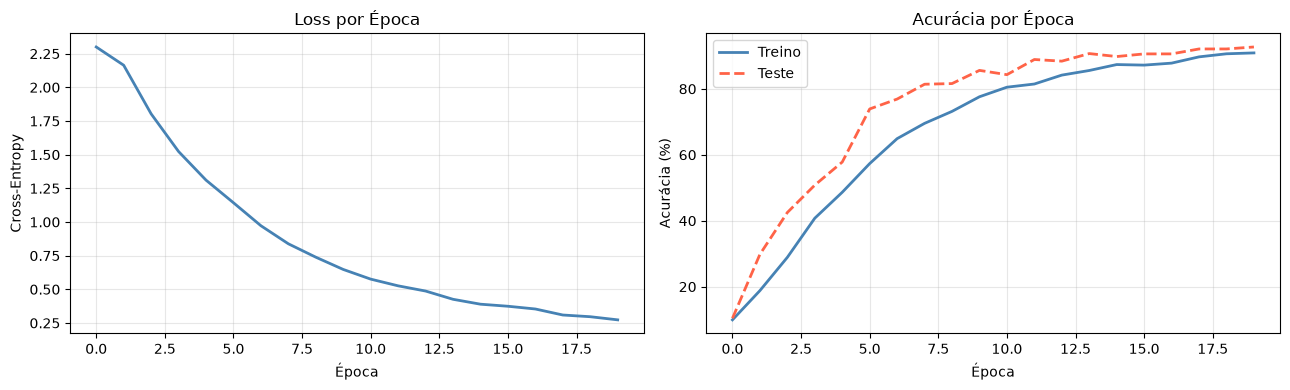

Acurácia final no teste: 92.7%


In [7]:
losses, accs_tr, accs_te = zip(*historico)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(losses, color='steelblue', lw=2)
axes[0].set_title('Loss por Época')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Cross-Entropy')
axes[0].grid(alpha=0.3)

axes[1].plot([a*100 for a in accs_tr], label='Treino', color='steelblue', lw=2)
axes[1].plot([a*100 for a in accs_te], label='Teste',  color='tomato', lw=2, linestyle='--')
axes[1].set_title('Acurácia por Época')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Acurácia (%)')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Acurácia final no teste: {accs_te[-1]*100:.1f}%')

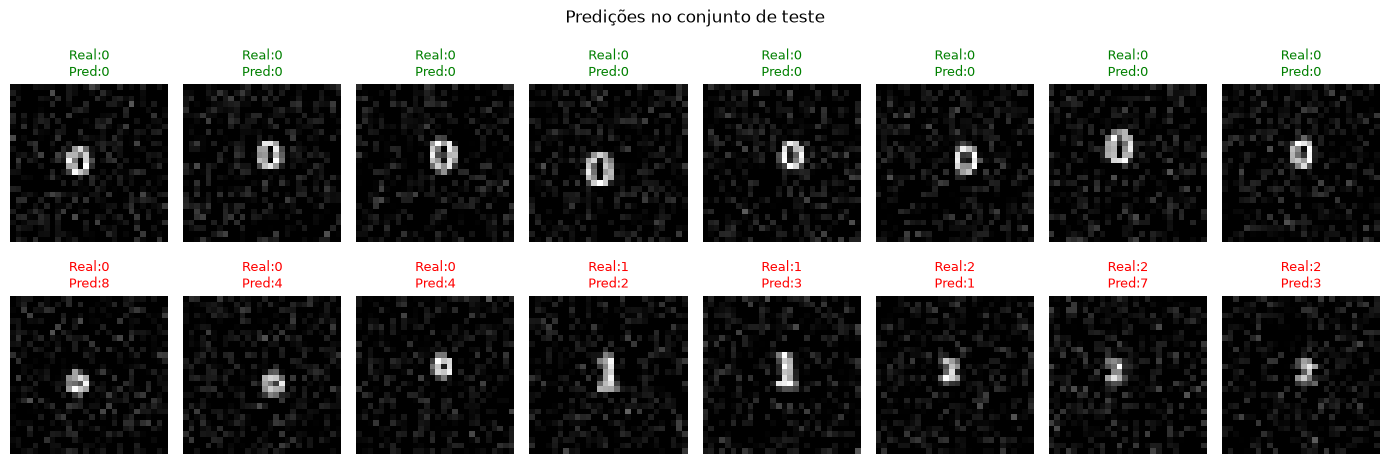

Acurácia por dígito:
  Dígito 0: 97.0%
  Dígito 1: 98.0%
  Dígito 2: 97.0%
  Dígito 3: 98.0%
  Dígito 4: 91.0%
  Dígito 5: 87.0%
  Dígito 6: 79.0%
  Dígito 7: 100.0%
  Dígito 8: 87.0%
  Dígito 9: 93.0%


In [8]:
# Predições no conjunto de teste
modelo.eval()
with torch.no_grad():
    logits = modelo(X_te.to(device))
    preds  = logits.argmax(1).cpu().numpy()

# Exemplos corretos e errados
corretos  = np.where(preds == y_test)[0]
erros     = np.where(preds != y_test)[0]

fig, axes = plt.subplots(2, 8, figsize=(14, 5))
for k, ax in enumerate(axes[0]):
    idx = corretos[k]
    ax.imshow(X_test[idx], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Real:{y_test[idx]}\nPred:{preds[idx]}', color='green', fontsize=9)
    ax.axis('off')

for k, ax in enumerate(axes[1]):
    if k < len(erros):
        idx = erros[k]
        ax.imshow(X_test[idx], cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'Real:{y_test[idx]}\nPred:{preds[idx]}', color='red', fontsize=9)
    ax.axis('off')

axes[0, 0].set_ylabel('Corretas', fontsize=10, fontweight='bold', color='green')
axes[1, 0].set_ylabel('Erradas',  fontsize=10, fontweight='bold', color='red')
plt.suptitle('Predições no conjunto de teste', fontsize=12)
plt.tight_layout()
plt.show()

# Acurácia por dígito
print('Acurácia por dígito:')
for d in range(10):
    mask = y_test == d
    ac   = (preds[mask] == y_test[mask]).mean() * 100
    print(f'  Dígito {d}: {ac:.1f}%')

### Salvando o modelo treinado

Treinar custa tempo, então o resultado vai para um arquivo. O que se guarda são os **pesos aprendidos** (o `state_dict`), e não a rede em si: para usar o modelo depois, cria-se a mesma arquitetura em código e carregam-se os pesos dentro dela. É assim que um modelo sai do notebook e vai para um aplicativo.

In [9]:
import os
os.makedirs('models', exist_ok=True)
torch.save({'model_state_dict': modelo.state_dict(),
            'accuracy_test':    accs_te[-1],
            'n_classes':        10},
           'models/cnn_digitos_sinteticos.pth')
print('Modelo salvo em models/cnn_digitos_sinteticos.pth')

Modelo salvo em models/cnn_digitos_sinteticos.pth


## 6. Conclusão

| Conceito | O que vimos na prática |
|---|---|
| **Dataset é só dado** | geramos 4 000 imagens com código, mostrando que um dataset é uma pilha de tabelas de números com rótulos |
| **Variação nos dados** | ruído, deslocamento e mudança de tamanho, para a rede aprender a forma em vez de decorar |
| **PyTorch** | camadas prontas no forward e backward automático com `loss.backward()` |
| **Lotes (batches)** | treinar 64 imagens por vez, mais rápido e mais estável |
| **Adam** | gradiente descendente com passo adaptativo por parâmetro |
| **Dropout** | desligar neurônios durante o treino para evitar overfitting |
| **Pipeline completo** | geração, tensores, DataLoader, CNN, treino, avaliação e modelo salvo |

Com 20 épocas, a rede chega a cerca de **94% de acerto** em imagens que nunca viu, usando 225 mil parâmetros.

### Para praticar

1. Aumente `n_por_classe` de `300` para `600`. Mais dados ajudam mais que mais épocas?
2. Aumente o `ruido` de `0.10` para `0.25` e veja quanto a acurácia cai.
3. Troque o `Adam` por `optim.SGD(modelo.parameters(), lr=0.01)` e compare as curvas.
4. Olhe a acurácia por dígito e tente explicar, observando as imagens, por que os piores são os piores.

---

**Próximo passo:** no notebook `03_cnn_datasets_reais.ipynb` trocamos os nossos dígitos fabricados por dois datasets reais e clássicos, o MNIST (dígitos escritos à mão) e o CIFAR-10 (fotos coloridas de objetos).